# Plot particle sizes from CSV

This notebook reads the exported per-particle size table and plots particle-size counts (weighted and unweighted) and particle size versus trajectory length. It does not rerun the analysis or call the pipeline plotting code.

Edit the settings in the next cell, then run the notebook. The statistical and filtering functions are defined in notebook cells so they can be inspected and reused.

In [6]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Change CSV_DIR to the analysis output folder and DIMENSION to x, y, or 2d.
CSV_DIR = Path("example/output_single_cpu")
if not CSV_DIR.exists() and Path("output_single_cpu").exists():
    CSV_DIR = Path("output_single_cpu")
DIMENSION = "x"

# Diameter-count plot settings.
HISTOGRAM_BIN_SIZE_NM = 0.5
HISTOGRAM_MAX_DIAMETER_NM = 150.0

# Particle-size-versus-trajectory-length plot filters.
TRAJECTORY_MAX_DIAMETER_NM = 150.0  # None disables this limit.
TRAJECTORY_PLOT_WEIGHTING = "unweighted"  # or "weighted" by valid frames (marker area).
FORCE_ULTRA_UNIFORM = True
ULTRA_UNIFORM_Z_MAX = 2.576
MIN_BRIGHTNESS = None  # None disables this filter.
MIN_TRAJECTORY_LENGTH = 1  # Uses valid_frames, the x-axis quantity.

if DIMENSION not in {"x", "y", "2d"}:
    raise ValueError("DIMENSION must be 'x', 'y', or '2d'.")
SIZE_CSV = CSV_DIR / f"particle_sizes_{DIMENSION}.csv"
if not SIZE_CSV.is_file():
    raise FileNotFoundError(f"Particle-size CSV not found: {SIZE_CSV}")

particle_sizes = pd.read_csv(SIZE_CSV)
required_columns = {"diameter_nm", "valid_frames", "diffusion_um2_s"}
missing_columns = required_columns.difference(particle_sizes.columns)
if missing_columns:
    raise ValueError(f"{SIZE_CSV.name} is missing columns: {sorted(missing_columns)}")
diameter_values = pd.to_numeric(particle_sizes["diameter_nm"], errors="coerce")
finite_diameters = diameter_values[np.isfinite(diameter_values) & (diameter_values > 0)]
if finite_diameters.empty:
    raise ValueError(f"{SIZE_CSV.name} has no positive finite diameter_nm values.")
if finite_diameters.median() < 1e-6:
    viscosity_pa_s = None
    temperature_k = None
    legacy_temperature_c = None
    legacy_viscosity = None
    config_file = CSV_DIR / "analysis_config.json"
    if config_file.is_file():
        config = json.loads(config_file.read_text(encoding="utf-8"))
        parameters = config.get("parameters", {})
        resolved = parameters.get("resolved_2_0", {})
        legacy_exp = parameters.get("legacy", {}).get("Exp", {})
        viscosity_pa_s = resolved.get("viscosity_pa_s")
        temperature_k = resolved.get("temperature_k")
        legacy_temperature_c = legacy_exp.get("Temperature")
        legacy_viscosity = legacy_exp.get("Viscosity")
    if viscosity_pa_s is None:
        parameter_file = CSV_DIR / "parameters.json"
        if parameter_file.is_file():
            parameters = json.loads(parameter_file.read_text(encoding="utf-8"))
            resolved = parameters.get("NanoObjectDetection_2_0", {})
            viscosity_pa_s = resolved.get("viscosity_pa_s")
            temperature_k = resolved.get("temperature_k")
            legacy_temperature_c = parameters.get("Exp", {}).get("Temperature")
            legacy_viscosity = parameters.get("Exp", {}).get("Viscosity")
    raise ValueError(
        f"The median diameter is {finite_diameters.median():.3g} nm, far below a usable nm-scale plot. "
        f"Saved settings: viscosity={viscosity_pa_s!r} Pa s, temperature={temperature_k!r} K; "
        f"legacy settings: Viscosity={legacy_viscosity!r}, Temperature={legacy_temperature_c!r} C. "
        "These output values are inconsistent for water and indicate an invalid or incompatible "
        "analysis run. Rerun the analysis with the current checkout before plotting."
    )
print(
    f"Loaded {len(particle_sizes)} particle records from {SIZE_CSV}; "
    f"diameter range: {finite_diameters.min():.3g}–{finite_diameters.max():.3g} nm"
)

Loaded 320 particle records from output_single_cpu/particle_sizes_x.csv; diameter range: 9.26–1.36e+03 nm


## Statistical and filtering functions

`size_distribution_statistics` reports the same inverse-diameter statistics shown on the count plots. `gaussian_fit` fits a Gaussian directly in diameter space, so its peak is at the diameter mean; the displayed median, inverse CV, and quantile intervals remain unchanged. `force_ultra_uniform_mask` implements the iterative median-centered rolling z-score filter used by the analysis.

In [7]:
def size_distribution_statistics(diameters_nm):
    """Return median, mean, inverse-size CV, and 1/2-sigma quantile intervals."""
    values = np.asarray(diameters_nm, dtype=float)
    values = values[np.isfinite(values) & (values > 0)]
    if values.size == 0:
        raise ValueError("At least one positive finite diameter is required.")

    inverse = 1000.0 / values
    inverse_mean = float(np.mean(inverse))
    inverse_std = float(np.std(inverse, ddof=1)) if values.size > 1 else 0.0
    q16, q84 = np.quantile(inverse, [0.158655, 0.841345])
    q023, q977 = np.quantile(inverse, [0.02275, 0.97725])
    return {
        "median_nm": float(1000.0 / np.median(inverse)),
        "mean_nm": float(np.mean(values)),
        "inverse_cv": inverse_std / inverse_mean if inverse_mean else float("nan"),
        "one_sigma_nm": (float(1000.0 / q84), float(1000.0 / q16)),
        "two_sigma_nm": (float(1000.0 / q977), float(1000.0 / q023)),
    }


def gaussian_fit(diameters_nm, peak, max_diameter_nm=300.0):
    """Return a Gaussian fit directly in diameter space, scaled to the histogram peak."""
    values = np.asarray(diameters_nm, dtype=float)
    values = values[np.isfinite(values) & (values > 0)]
    if values.size < 2 or np.std(values) == 0 or peak <= 0:
        return np.array([]), np.array([])

    lower = max(float(np.min(values)) * 0.5, 1.0)
    upper = min(float(np.max(values)) * 1.5, float(max_diameter_nm))
    if upper <= lower:
        return np.array([]), np.array([])
    grid = np.linspace(lower, upper, 1000)
    mean = float(np.mean(values))
    std = float(np.std(values, ddof=1))
    density = np.exp(-0.5 * ((grid - mean) / std) ** 2)
    return grid, density / density.max() * peak


def median_centered_rolling_spread(values):
    """Calculate the median-centered RMS spread used by the uniformity filter."""
    values = np.asarray(values, dtype=float)
    return float(np.sqrt(np.mean((values - np.median(values)) ** 2)))


def remove_rolling_z_outliers(data, column, window_size, z_max):
    """Iteratively remove rows whose rolling median-centered z-score reaches z_max."""
    data = data.copy()
    while len(data):
        spread = data[column].rolling(
            window_size, min_periods=1, center=True
        ).apply(median_centered_rolling_spread, raw=True)
        z_score = (data[column] - data[column].median()).abs() / spread
        if z_score.max() < z_max:
            break
        data = data[z_score < z_max]
    return data


def force_ultra_uniform_mask(data, z_max=2.576):
    """Return the analysis-compatible force-ultra-uniform particle mask."""
    valid = data["diameter_nm"].notna() & data["diffusion_um2_s"].notna()
    valid &= np.isfinite(data["diameter_nm"]) & np.isfinite(data["diffusion_um2_s"])
    valid &= (data["diameter_nm"] > 0) & (data["diffusion_um2_s"] > 0)
    valid_data = data.loc[valid]
    particle_count = len(valid_data)
    if particle_count < 10:
        return pd.Series(True, index=data.index)

    window_size = 100 if particle_count >= 100 else particle_count - 2
    ordered = valid_data[["diameter_nm", "diffusion_um2_s", "valid_frames"]].sort_values(
        "valid_frames"
    )
    ordered = remove_rolling_z_outliers(ordered, "diameter_nm", window_size, z_max)
    ordered = remove_rolling_z_outliers(ordered, "diffusion_um2_s", window_size, z_max)
    keep = pd.Series(False, index=data.index)
    keep.loc[ordered.index] = True
    keep.loc[~data.index.isin(valid_data.index)] = True
    return keep

## Diameter counts

The unweighted histogram counts each particle once. The weighted histogram counts each particle once per valid frame. Both use the configured bin size and maximum diameter.

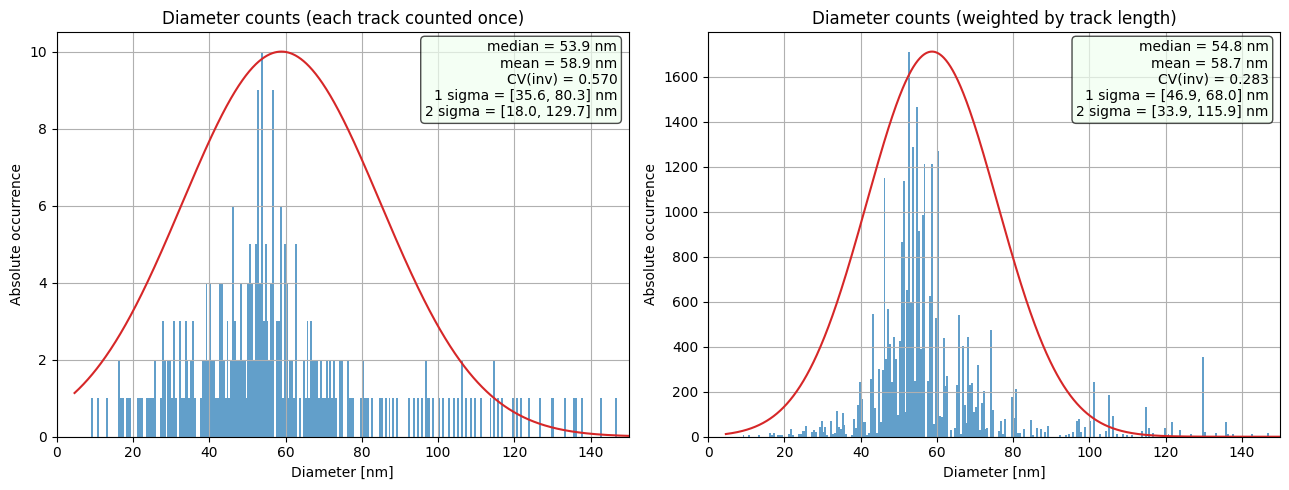

{'unweighted': {'median_nm': 53.86525508920154,
  'mean_nm': 58.89415650623488,
  'inverse_cv': 0.5696504376786178,
  'one_sigma_nm': (35.58238699310327, 80.30959251938394),
  'two_sigma_nm': (18.021549503162372, 129.65059509517323)},
 'weighted': {'median_nm': 54.80460037460063,
  'mean_nm': 58.70781971532364,
  'inverse_cv': 0.2832230850659106,
  'one_sigma_nm': (46.917187004622726, 68.04130454832071),
  'two_sigma_nm': (33.931220406477955, 115.86606102823953)}}

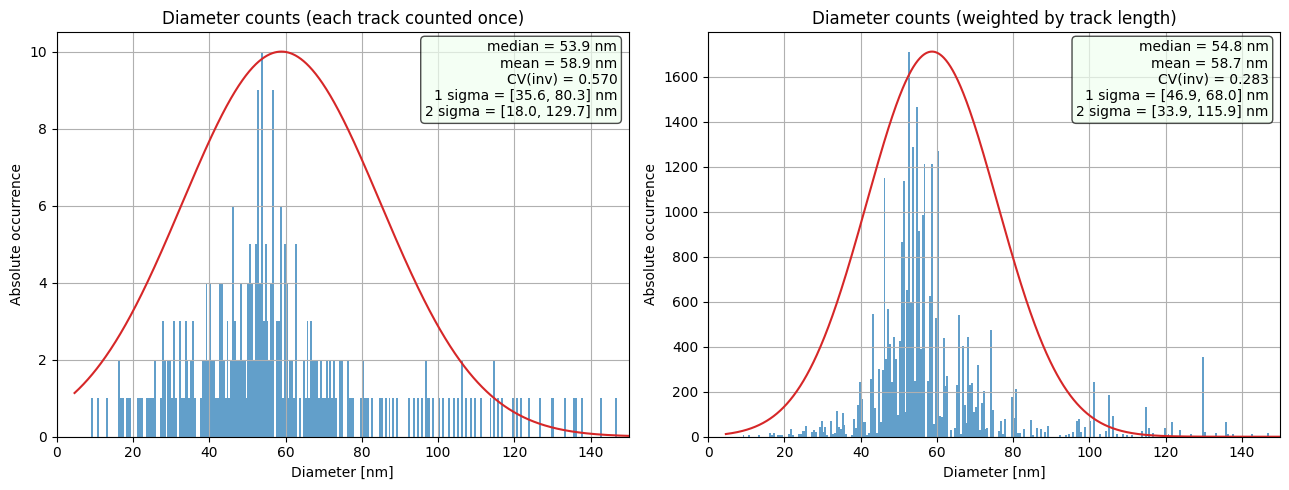

In [8]:
def plot_diameter_counts(
    data,
    bin_size_nm=0.5,
    max_diameter_nm=300.0,
):
    """Display weighted and unweighted diameter counts with fit and statistics."""
    if bin_size_nm <= 0 or max_diameter_nm <= 0:
        raise ValueError("Bin size and maximum diameter must be positive.")
    required = {"diameter_nm", "valid_frames"}
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f"Data is missing columns: {sorted(missing)}")

    valid = data.loc[
        np.isfinite(data["diameter_nm"])
        & np.isfinite(data["valid_frames"])
        & (data["diameter_nm"] > 0)
        & (data["diameter_nm"] <= max_diameter_nm)
        & (data["valid_frames"] >= 1)
    ].copy()
    valid["valid_frames"] = valid["valid_frames"].astype(int)
    bins = np.arange(0, max_diameter_nm + bin_size_nm, bin_size_nm)
    if bins.size < 2 or bins[-1] < max_diameter_nm:
        bins = np.append(bins, max_diameter_nm)

    figure, axes = plt.subplots(1, 2, figsize=(13, 5))
    statistics_by_weighting = {}
    for axis, weighted in zip(axes, (False, True)):
        diameters = valid["diameter_nm"].to_numpy(float)
        weights = valid["valid_frames"].to_numpy(int) if weighted else None
        counts, _, _ = axis.hist(
            diameters, bins=bins, weights=weights,
            color="#1f77b4", edgecolor="none", linewidth=0, alpha=0.7,
        )
        expanded = np.repeat(diameters, weights) if weighted else diameters
        if expanded.size:
            stats = size_distribution_statistics(expanded)
            statistics_by_weighting["weighted" if weighted else "unweighted"] = stats
            grid, fit = gaussian_fit(
                expanded, counts.max(), max_diameter_nm=max_diameter_nm
            )
            if grid.size:
                axis.plot(grid, fit, color="C3")
            one_sigma = stats["one_sigma_nm"]
            two_sigma = stats["two_sigma_nm"]
            stats_text = (
                f"median = {stats['median_nm']:.1f} nm\n"
                f"mean = {stats['mean_nm']:.1f} nm\n"
                f"CV(inv) = {stats['inverse_cv']:.3f}\n"
                f"1 sigma = [{one_sigma[0]:.1f}, {one_sigma[1]:.1f}] nm\n"
                f"2 sigma = [{two_sigma[0]:.1f}, {two_sigma[1]:.1f}] nm"
            )
            axis.text(
                0.98, 0.98, stats_text, transform=axis.transAxes,
                ha="right", va="top",
                bbox={"boxstyle": "round", "facecolor": "honeydew", "alpha": 0.7},
            )
        else:
            axis.text(0.5, 0.5, "No particles in range", ha="center", va="center")
        weighting_label = "weighted by track length" if weighted else "each track counted once"
        axis.set(
            title=f"Diameter counts ({weighting_label})",
            xlabel="Diameter [nm]",
            ylabel="Absolute occurrence",
            xlim=(0, max_diameter_nm),
        )
        axis.grid(True)

    figure.tight_layout()
    return figure, axes, statistics_by_weighting


histogram_figure, histogram_axes, histogram_statistics = plot_diameter_counts(
    particle_sizes,
    bin_size_nm=HISTOGRAM_BIN_SIZE_NM,
    max_diameter_nm=HISTOGRAM_MAX_DIAMETER_NM,
)
display(histogram_figure)
histogram_statistics

## Particle size versus trajectory length

This scatter plot uses valid frame count on a logarithmic x-axis, diameter on a logarithmic y-axis, and mean brightness for the color scale. Choose unweighted (one equal-size marker per particle) or weighted (marker area proportional to valid frames). The filters below are independent of the diameter-count plots.

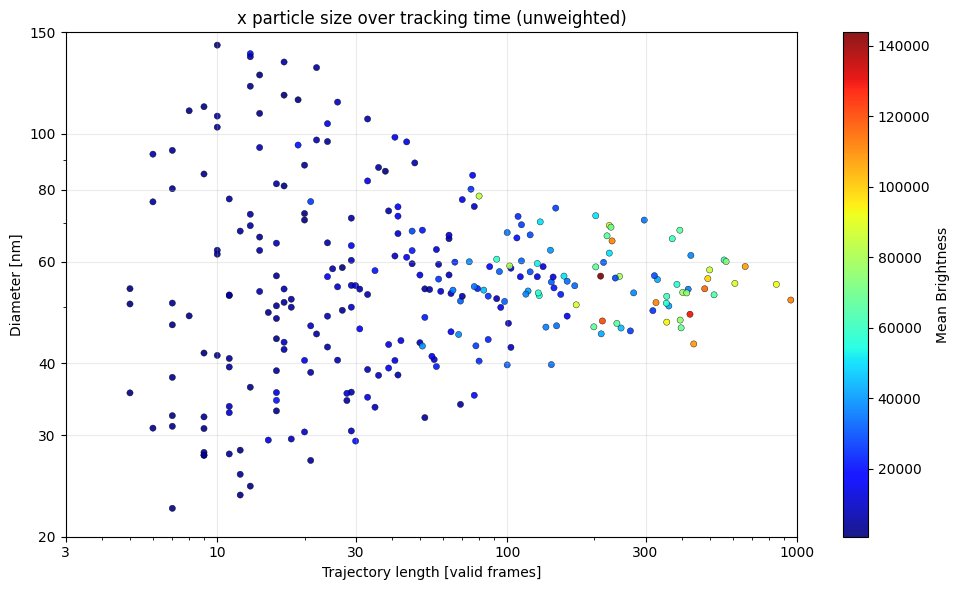

Particles shown: 272


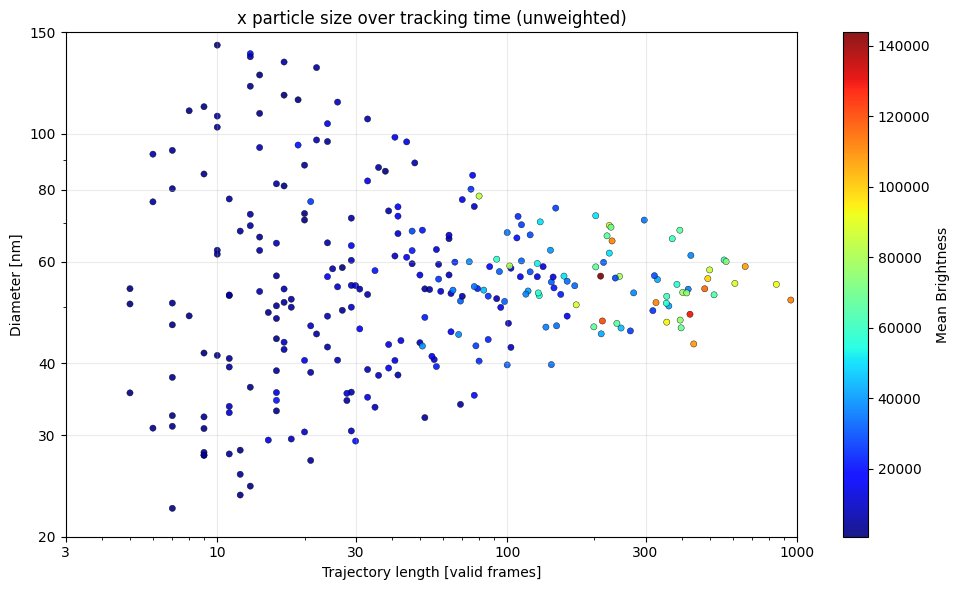

In [9]:
def filter_particle_sizes(
    data,
    max_diameter_nm=300.0,
    force_ultra_uniform=False,
    min_brightness=None,
    min_trajectory_length=1,
    z_max=2.576,
):
    """Apply the configurable filters for the size-versus-trajectory plot."""
    filtered = data.loc[
        np.isfinite(data["diameter_nm"])
        & np.isfinite(data["valid_frames"])
        & (data["diameter_nm"] > 0)
        & (data["valid_frames"] > 0)
    ].copy()
    if max_diameter_nm is not None:
        filtered = filtered[filtered["diameter_nm"] <= max_diameter_nm]
    if force_ultra_uniform:
        filtered = filtered.loc[force_ultra_uniform_mask(filtered, z_max=z_max)]
    if min_brightness is not None:
        if "mean_brightness" not in filtered:
            raise ValueError("The CSV needs mean_brightness for the brightness filter.")
        filtered = filtered[
            np.isfinite(filtered["mean_brightness"])
            & (filtered["mean_brightness"] >= min_brightness)
        ]
    if min_trajectory_length is not None:
        filtered = filtered[filtered["valid_frames"] >= min_trajectory_length]
    return filtered


def set_legacy_log_ticks(axis, x_values, y_values):
    """Use explicit logarithmic tick labels like the original trajectory-size plot."""
    from matplotlib.ticker import NullFormatter, ScalarFormatter

    x_ticks = np.array([1, 3, 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000])
    y_ticks = np.array([1, 2, 3, 4, 6, 10, 15, 20, 30, 40, 60, 80, 100, 150, 200, 300, 400, 600, 800, 1000])
    x_low = x_ticks[x_ticks <= x_values.min()][-1] if (x_ticks <= x_values.min()).any() else x_ticks[0]
    x_high = x_ticks[x_ticks >= x_values.max()][0] if (x_ticks >= x_values.max()).any() else x_ticks[-1]
    y_low = y_ticks[y_ticks <= y_values.min()][-1] if (y_ticks <= y_values.min()).any() else y_ticks[0]
    y_high = y_ticks[y_ticks >= y_values.max()][0] if (y_ticks >= y_values.max()).any() else y_ticks[-1]
    axis.set_xticks(x_ticks)
    axis.set_yticks(y_ticks)
    axis.set_xlim(x_low, x_high)
    axis.set_ylim(y_low, y_high)
    for ticks in (axis.xaxis, axis.yaxis):
        ticks.set_major_formatter(ScalarFormatter())
        ticks.set_minor_formatter(NullFormatter())


def plot_particle_size_over_trajectory_length(
    data,
    max_diameter_nm=300.0,
    force_ultra_uniform=False,
    min_brightness=None,
    min_trajectory_length=1,
    weighting="unweighted",
    z_max=2.576,
):
    """Display particle diameter versus trajectory length with optional frame weighting."""
    if weighting not in {"weighted", "unweighted"}:
        raise ValueError("weighting must be 'weighted' or 'unweighted'.")
    filtered = filter_particle_sizes(
        data,
        max_diameter_nm=max_diameter_nm,
        force_ultra_uniform=force_ultra_uniform,
        min_brightness=min_brightness,
        min_trajectory_length=min_trajectory_length,
        z_max=z_max,
    )
    figure, axis = plt.subplots(figsize=(10, 6))
    if filtered.empty:
        axis.text(0.5, 0.5, "No particles pass the selected filters", ha="center", va="center")
        axis.set_axis_off()
        return figure, filtered

    brightness = (
        filtered["mean_brightness"].to_numpy(float)
        if "mean_brightness" in filtered
        else np.ones(len(filtered))
    )
    marker_sizes = (
        180.0 * filtered["valid_frames"].to_numpy(float)
        / filtered["valid_frames"].max()
        if weighting == "weighted"
        else 20
    )
    scatter = axis.scatter(
        filtered["valid_frames"], filtered["diameter_nm"],
        s=marker_sizes, c=brightness, cmap="jet", alpha=0.9,
        edgecolors="black", linewidths=0.3,
    )
    colorbar = figure.colorbar(scatter, ax=axis)
    colorbar.set_label("Mean Brightness")
    axis.set(
        title=f"{DIMENSION} particle size over tracking time ({weighting})",
        xlabel="Trajectory length [valid frames]",
        ylabel="Diameter [nm]",
        xscale="log",
        yscale="log",
    )
    set_legacy_log_ticks(
        axis,
        filtered["valid_frames"].to_numpy(float),
        filtered["diameter_nm"].to_numpy(float),
    )
    axis.grid(alpha=0.25)
    figure.tight_layout()
    return figure, filtered


trajectory_figure, trajectory_plot_data = plot_particle_size_over_trajectory_length(
    particle_sizes,
    max_diameter_nm=TRAJECTORY_MAX_DIAMETER_NM,
    force_ultra_uniform=FORCE_ULTRA_UNIFORM,
    min_brightness=MIN_BRIGHTNESS,
    min_trajectory_length=MIN_TRAJECTORY_LENGTH,
    weighting=TRAJECTORY_PLOT_WEIGHTING,
    z_max=ULTRA_UNIFORM_Z_MAX,
)
display(trajectory_figure)
print(f"Particles shown: {len(trajectory_plot_data)}")